# Day 1, session 1C: Confusion matrices and decision thresholds

**Estimated core time:** 30 minutes  
**Dataset:** `data/customer_churn.csv`  
**Starting point:** repeat the leakage-safe logistic-regression workflow from sessions 1A + 1B

The executable cells are intentionally empty. This lesson separates a model's probability estimates from the decision rule used to turn them into actions.

## Why this matters

A classifier does not inherently know whether missing a churner is worse than contacting a customer who would have stayed. It estimates scores or probabilities; people choose the threshold that converts those probabilities into decisions.

Interviewers often care more about whether you can explain false positives, false negatives, and threshold trade-offs than whether you remember a particular function name.

## Learning objectives

By the end, you should be able to:

1. Reconstruct and navigate a preprocessing-plus-model pipeline.
2. Read a binary confusion matrix and derive precision and recall from its counts.
3. Convert churn probabilities into class predictions at different thresholds.
4. Choose a threshold using explicit error costs without tuning on the test set.

## R-to-Python bridge

| Statistical idea | Python/scikit-learn expression |
|---|---|
| Classification table | `confusion_matrix(y_true, y_pred)` |
| Probability cutoff | `(probability >= threshold).astype(int)` |
| Sensitivity | recall = TP / (TP + FN) |
| Positive predictive value | precision = TP / (TP + FP) |
| Decision rule | model probability plus a chosen threshold |

A threshold is not a model coefficient. Changing it does not refit the logistic regression; it changes how the same probabilities are converted into actions.

## Suggested pacing

- 0–10 min: reconstruct the pipeline from memory
- 10–17 min: confusion matrix
- 17–25 min: threshold comparison and business costs
- 25–30 min: leakage check and interview explanation

The reconstruction may take longer today. That is useful repetition, not failure.

## Task 1 — Retrieval: reconstruct the fitted workflow

Using `data/customer_churn.csv`, recreate the following objects:

- `X` and `y`, excluding `customer_id` from the predictors
- seven numeric and three categorical feature-name lists
- stratified 80/20 train/test data with `random_state=42`
- numeric pipeline: median imputation then scaling
- categorical pipeline: most-frequent imputation then one-hot encoding
- `preprocessor` and `logistic_pipeline`
- fitted pipeline, test-set class predictions, and positive-class probabilities

Import the required pandas and scikit-learn objects yourself. For today's new work, also import:

```python
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    roc_auc_score,
)
```

Try from memory first. If stuck after five minutes, consult Task 9 in the previous notebook once, close it, and continue.

**Self-checks:**

- `X_train.shape == (2000, 10)`
- transformed training shape is `(2000, 16)`
- class predictions and positive probabilities each have shape `(500,)`
- ROC AUC calculated from probabilities is approximately 0.82

In [28]:
import missingno
import pandas as pd
from plotnine import (
    ggplot,
    aes,
    geom_histogram,
    geom_bar,
    labs,
    theme_minimal
)

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
import missingno as msno

churn = pd.read_csv('data/customer_churn.csv')

X = churn.drop(columns=['customer_id', 'churned'])
y = churn['churned']
numeric_features = X.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X.select_dtypes(include = ['str']).columns

# Test train split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42, stratify = y) 

In [16]:
churn.isna().sum().sort_values(ascending = False)

monthly_usage_hours    107
age                     83
payment_method          48
customer_id              0
household_size           0
tenure_months            0
contract                 0
internet_service         0
monthly_charge_eur       0
support_calls_6m         0
late_payments_12m        0
churned                  0
dtype: int64

In [17]:
# Preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])  

preprocessor = ColumnTransformer(transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])  

# Apply the model
model1 = logistic_pipeline.fit(X_train, y_train)

In [18]:
print(X_train.shape)
print(logistic_pipeline.named_steps['preprocessor'].transform(X_train).shape)

class_predictions = model1.predict(X_test)
class_probabilities = model1.predict_proba(X_test)[:, 1]
print(class_predictions.shape)
print(class_probabilities.shape)

(2000, 10)
(2000, 16)
(500,)
(500,)


## Task 2 — Build and interpret a confusion matrix

Create the confusion matrix for the default class predictions:

```python
matrix = confusion_matrix(y_test, logistic_predictions)
matrix
```

For binary classes ordered as `[0, 1]`, scikit-learn arranges it as:

```text
                 Predicted 0    Predicted 1
Actual 0              TN             FP
Actual 1              FN             TP
```

Extract the four counts with:

```python
tn, fp, fn, tp = matrix.ravel()
```

Then:

1. Calculate recall manually from `tp` and `fn`.
2. Calculate precision manually from `tp` and `fp`.
3. Verify both against scikit-learn.
4. Display the matrix with `ConfusionMatrixDisplay`.
5. Write one sentence explaining the false negatives in this churn setting.

**Predict before running:** because recall was around 0.40 previously, should `fn` be larger or smaller than `tp`?

In [20]:
matrix = confusion_matrix(y_test, class_predictions)
matrix

array([[357,  24],
       [ 72,  47]])

In [43]:
true_negatives = matrix[0, 0]  # True Negatives
false_positives = matrix[0, 1]  # False Positives
false_negatives = matrix[1, 0]  # False Negatives
true_positives = matrix[1, 1]  # True Positives

manual_precision = true_positives / (true_positives + false_positives) 
manual_recall = true_positives / (true_positives + false_negatives)

precision = precision_score(y_test, class_predictions)
recall = recall_score(y_test, class_predictions)  
churned_total = (class_predictions == 1).sum()

print(f"Manual Precision: {manual_precision:.4f}")
print(f"Sklearn Precision: {precision:.4f}")
print(f"Manual Recall: {manual_recall:.4f}")
print(f"Sklearn Recall: {recall:.4f}")

Manual Precision: 0.6620
Sklearn Precision: 0.6620
Manual Recall: 0.3950
Sklearn Recall: 0.3950


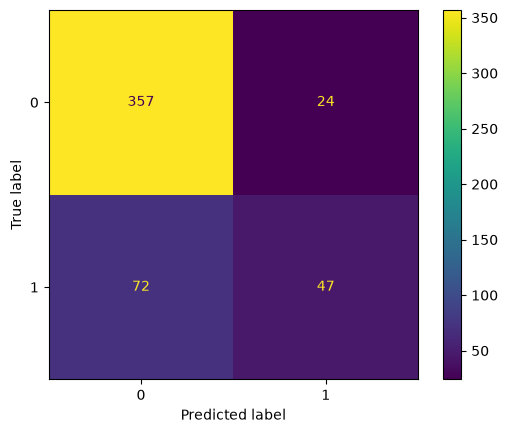

In [30]:
ConfusionMatrixDisplay(matrix).plot()


false negatives are the values where the model predicted a 0, when in fact it was truly a 1 in the data

## Task 3 — Compare three decision thresholds

Use the same positive-class probabilities to create predictions at thresholds 0.30, 0.50, and 0.70:

```python
threshold_predictions = (positive_probabilities >= threshold).astype(int)
```

For each threshold, calculate:

- precision
- recall
- number of customers predicted to churn

Store the results as a pandas `DataFrame` with one row per threshold.

You may use a small `for` loop and append dictionaries to a list:

```python
rows = []

for threshold in thresholds:
    # create predictions
    # append a dictionary of results

threshold_results = pd.DataFrame(rows)
```

Before running, predict the direction of each quantity as the threshold increases. Then explain the observed trade-off in plain language.

In [44]:
pred_03 = (class_probabilities >= 0.3).astype(int)
pred_05 = (class_probabilities >= 0.5).astype(int)
pred_07 = (class_probabilities >= 0.7).astype(int)


recall_03 = recall_score(y_test, pred_03)
recall_05 = recall_score(y_test, pred_05)
recall_07 = recall_score(y_test, pred_07)

precision_03 = precision_score(y_test, pred_03)
precision_05 = precision_score(y_test, pred_05)
precision_07 = precision_score(y_test, pred_07)

churn_03 = (pred_03 == 1).sum()
churn_05 = (pred_05 == 1).sum()
churn_07 = (pred_07 == 1).sum()


print(f"Original : Recall = {recall:.4f}, Precision = {precision:.4f}, Predicted Churn = {churned_total}")
print(f"Threshold 0.3: Recall = {recall_03:.4f}, Precision = {precision_03:.4f}, Predicted Churn = {churn_03}")
print(f"Threshold 0.5: Recall = {recall_05:.4f}, Precision = {precision_05:.4f}, Predicted Churn = {churn_05}")
print(f"Threshold 0.7: Recall = {recall_07:.4f}, Precision = {precision_07:.4f}, Predicted Churn = {churn_07}")




Original : Recall = 0.3950, Precision = 0.6620, Predicted Churn = 71
Threshold 0.3: Recall = 0.6891, Precision = 0.5430, Predicted Churn = 151
Threshold 0.5: Recall = 0.3950, Precision = 0.6620, Predicted Churn = 71
Threshold 0.7: Recall = 0.1849, Precision = 0.8800, Predicted Churn = 25


## Task 4 — Attach costs to errors

Assume:

- Missing a real churner costs €250: each false negative costs 250.
- Contacting a customer who would have stayed costs €20: each false positive costs 20.

For each threshold from Task 3:

1. Create its confusion matrix.
2. Extract `fp` and `fn`.
3. Calculate `total_cost = 20 * fp + 250 * fn`.
4. Add false positives, false negatives, and total cost to a comparison table.
5. Select the threshold with the lowest cost.

**Interpretation requirement:** explain why the cost-minimizing threshold need not be 0.50. State whose costs or assumptions would need validation before using this rule in reality.

## Task 5 — Debug threshold-selection leakage

An AI assistant proposes:

```python
for threshold in possible_thresholds:
    predictions = (test_probabilities >= threshold).astype(int)
    test_cost = calculate_cost(y_test, predictions)
    keep_the_threshold_with_lowest_test_cost()

report_that_same_test_cost_as_final_performance()
```

Answer in words and then write a safe high-level alternative:

1. What information leaked?
2. Why will the reported performance be optimistic?
3. Which data should choose the threshold?
4. What should the untouched test set be used for?

A useful conceptual split is:

```text
training data   → fit model parameters
validation data → choose threshold or hyperparameters
test data       → one final evaluation
```

You do not need to implement a three-way split yet; focus on explaining the safe sequence.

## Retrieval practice — Task 6: navigate the fitted object

Without looking at the previous notebook, obtain and display:

1. The outer pipeline's registered step names.
2. The fitted numeric transformer.
3. The transformed test-matrix shape.
4. The logistic-regression coefficient-matrix shape.

Useful distinction:

- `Pipeline` exposes `named_steps`.
- A fitted `ColumnTransformer` exposes `named_transformers_`.

Then explain why the logistic-regression object has `predict` but not `transform`, while the preprocessor has `transform`.

## Interview questions

Answer aloud or add a markdown cell:

1. A model has high ROC AUC but low recall at threshold 0.50. Is that contradictory?
2. What happens to false positives and false negatives when the threshold is lowered?
3. Why must threshold selection reflect business or scientific costs?
4. Why is choosing a threshold on the test set a form of overfitting?

Aim for answers that mention probabilities, decisions, and unseen-data evaluation.

## Self-check and reflection

Record:

- Confidence from 1–5:
- Could you reconstruct the pipeline with less help than yesterday?
- Which confusion-matrix cell is easiest to mix up?
- Can you explain why ROC AUC and recall at 0.50 measure different things?
- What should be repeated in the next session?
- Approximate time spent:

Tell Codex when you are done; completion is recorded only after your attempt.

## Optional extension — Explore more thresholds

Create thresholds from 0.10 to 0.90 in steps of 0.05 and calculate precision, recall, false positives, false negatives, and cost for each.

Use plotnine to plot threshold against precision and recall. Add a vertical line or annotation for your selected threshold if you can discover the appropriate plotnine layer.

This extension is outside the core 30 minutes.

## Finish line

You should now be able to explain:

**The model estimates probabilities. The threshold creates decisions. The confusion matrix counts the consequences. The cost function expresses which consequences matter.**

Next, Day 2 begins reliable preprocessing and validation workflows in more depth.